In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Set the dataset path
DATA_PATH = Path("uber.csv")

# Search for the dataset if it is not in the current folder
if not DATA_PATH.exists():
    csv_files = list(Path(".").rglob("*.csv"))
    uber_files = [
        file for file in csv_files
        if "uber" in file.name.lower()
    ]

    if uber_files:
        DATA_PATH = uber_files[0]
    elif len(csv_files) == 1:
        DATA_PATH = csv_files[0]
    else:
        print("CSV files found:", [str(f) for f in csv_files])
        raise FileNotFoundError(
            "Please download the Uber dataset and set DATA_PATH correctly."
        )

print("Loading dataset from:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Remove any unnecessary index column
df.drop(
    columns=[col for col in df.columns if col.startswith("unnamed")],
    inplace=True,
    errors="ignore"
)

print("Dataset loaded successfully!")

Loading dataset from: uber.csv
Dataset loaded successfully!


In [4]:
print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical summary:")
display(df.describe().T)

First five rows:


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1.0
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1.0
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1.0
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3.0
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5.0



Dataset shape: (62527, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62527 entries, 0 to 62526
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   key                62527 non-null  object 
 1   fare_amount        62527 non-null  float64
 2   pickup_datetime    62527 non-null  object 
 3   pickup_longitude   62527 non-null  float64
 4   pickup_latitude    62526 non-null  float64
 5   dropoff_longitude  62526 non-null  float64
 6   dropoff_latitude   62526 non-null  float64
 7   passenger_count    62526 non-null  float64
dtypes: float64(6), object(2)
memory usage: 3.8+ MB

Missing values in each column:


,Missing Values
key,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,1
dropoff_longitude,1
dropoff_latitude,1
passenger_count,1



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
fare_amount,62527.0,11.429161,10.036933,0.000000,6.000000,8.500000,12.700000,350.000000
pickup_longitude,62527.0,-72.538940,11.073770,-748.016667,-73.992086,-73.981830,-73.967173,40.808425
pickup_latitude,62526.0,39.937683,6.472558,-74.015515,40.734735,40.752493,40.767116,404.433332
dropoff_longitude,62526.0,-72.550323,10.663850,-737.916665,-73.991462,-73.980125,-73.963706,40.828377
dropoff_latitude,62526.0,39.934674,6.111677,-74.008745,40.733614,40.752943,40.768170,45.031598
passenger_count,62526.0,1.676758,1.296592,0.000000,1.000000,1.000000,2.000000,6.000000


In [5]:
# Check for the expected columns
required_columns = [
    "fare_amount",
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"The following required columns are missing: {missing_columns}"
    )

# Convert numerical columns
numeric_columns = [
    "fare_amount",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce",
    utc=True
)

# Remove rows with missing values in essential columns
df.dropna(subset=required_columns, inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Extract time-based features
df["hour"] = df["pickup_datetime"].dt.hour
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

# The original timestamp and identifier are not needed as model inputs
df.drop(
    columns=["pickup_datetime", "key"],
    inplace=True,
    errors="ignore"
)

df.reset_index(drop=True, inplace=True)

print("Data preprocessing completed.")
print("Shape after preprocessing:", df.shape)

display(df.head())

Data preprocessing completed.
Shape after preprocessing: (62526, 10)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,month,year
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1.0,19,3,5,2015
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1.0,20,4,7,2009
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1.0,21,0,8,2009
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,4,6,2009
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5.0,17,3,8,2014


In [6]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the great-circle distance between two coordinates.
    Returns distance in kilometres.
    """
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 2 * 6371 * np.arcsin(np.sqrt(a))


df["trip_distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

print("Trip distance calculated successfully.")

display(
    df[
        [
            "pickup_latitude",
            "pickup_longitude",
            "dropoff_latitude",
            "dropoff_longitude",
            "trip_distance_km",
            "fare_amount"
        ]
    ].head()
)

Trip distance calculated successfully.


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,trip_distance_km,fare_amount
0,40.738354,-73.999817,40.723217,-73.999512,1.683323,7.5
1,40.728225,-73.994355,40.750325,-73.994710,2.457590,7.7
2,40.740770,-74.005043,40.772647,-73.962565,5.036377,12.9
3,40.790844,-73.976124,40.803349,-73.965316,1.661683,5.3
4,40.744085,-73.925023,40.761247,-73.973082,4.475450,16.0


In [7]:
def iqr_outlier_summary(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (series < lower_bound)
        | (series > upper_bound)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage (%)": outliers.mean() * 100
    }


outlier_results = pd.DataFrame({
    "Fare Amount": iqr_outlier_summary(df["fare_amount"]),
    "Trip Distance (km)": iqr_outlier_summary(df["trip_distance_km"])
}).T

print("IQR Outlier Analysis:")
display(outlier_results.round(2))

IQR Outlier Analysis:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
Fare Amount,6.00,12.7,6.70,-4.05,22.75,5250.0,8.4
Trip Distance (km),1.22,3.9,2.68,-2.80,7.93,5189.0,8.3


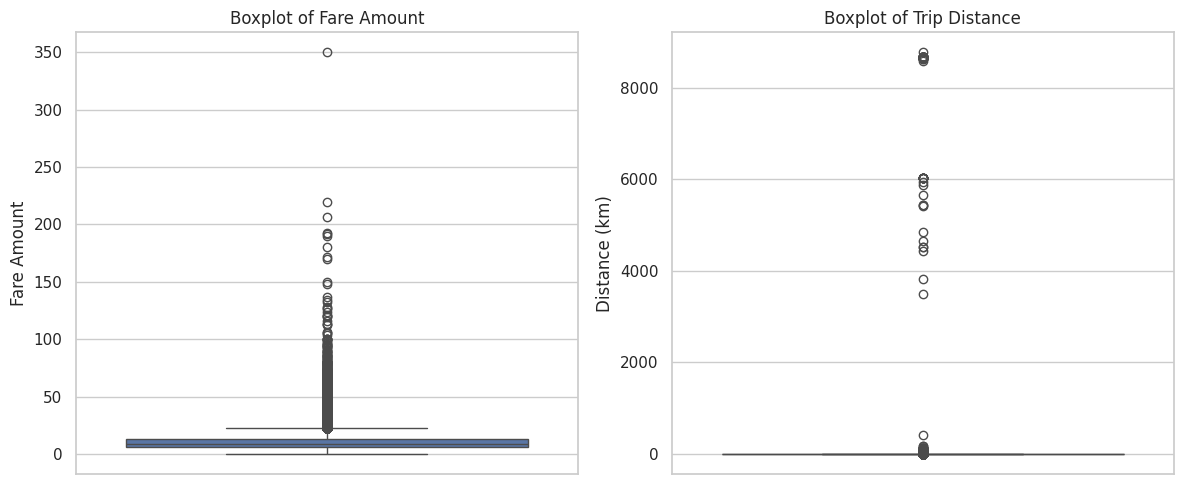

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    y=df["fare_amount"],
    ax=axes[0]
)
axes[0].set_title("Boxplot of Fare Amount")
axes[0].set_ylabel("Fare Amount")

sns.boxplot(
    y=df["trip_distance_km"],
    ax=axes[1]
)
axes[1].set_title("Boxplot of Trip Distance")
axes[1].set_ylabel("Distance (km)")

plt.tight_layout()
plt.show()

In [9]:
rows_before_cleaning = len(df)

valid_records = (
    (df["fare_amount"] > 0)
    & (df["fare_amount"] <= 100)

    & df["pickup_longitude"].between(-75.5, -72.5)
    & df["dropoff_longitude"].between(-75.5, -72.5)

    & df["pickup_latitude"].between(40.0, 42.5)
    & df["dropoff_latitude"].between(40.0, 42.5)

    & df["passenger_count"].isin([1, 2, 3, 4, 5, 6])

    & (df["trip_distance_km"] > 0.1)
    & (df["trip_distance_km"] <= 100)
)

df = df.loc[valid_records].copy()
df.reset_index(drop=True, inplace=True)

rows_after_cleaning = len(df)
rows_removed = rows_before_cleaning - rows_after_cleaning

print("Outlier and data quality filtering completed.")
print("Rows before filtering:", rows_before_cleaning)
print("Rows after filtering:", rows_after_cleaning)
print("Rows removed:", rows_removed)
print(
    "Percentage of rows removed:",
    round(rows_removed / rows_before_cleaning * 100, 2),
    "%"
)

display(df.head())

Outlier and data quality filtering completed.
Rows before filtering: 62526
Rows after filtering: 59997
Rows removed: 2529
Percentage of rows removed: 4.04 %


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,month,year,trip_distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1.0,19,3,5,2015,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1.0,20,4,7,2009,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1.0,21,0,8,2009,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,4,6,2009,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5.0,17,3,8,2014,4.475450


Correlation matrix:


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,month,year,trip_distance_km,fare_amount
pickup_longitude,1.000,-0.023,0.319,0.054,-0.001,0.018,-0.026,0.006,0.015,0.450,0.422
pickup_latitude,-0.023,1.000,0.055,0.422,-0.007,0.030,-0.043,-0.002,-0.008,-0.222,-0.217
dropoff_longitude,0.319,0.055,1.000,0.147,-0.000,-0.049,0.001,0.010,0.012,0.374,0.313
dropoff_latitude,0.054,0.422,0.147,1.000,-0.003,0.024,-0.032,-0.006,-0.002,-0.153,-0.187
passenger_count,-0.001,-0.007,-0.000,-0.003,1.000,0.015,0.034,0.009,-0.001,0.009,0.013
hour,0.018,0.030,-0.049,0.024,0.015,1.000,-0.092,-0.007,0.002,-0.026,-0.013
day_of_week,-0.026,-0.043,0.001,-0.032,0.034,-0.092,1.000,-0.007,0.000,0.011,-0.001
month,0.006,-0.002,0.010,-0.006,0.009,-0.007,-0.007,1.000,-0.117,0.018,0.030
year,0.015,-0.008,0.012,-0.002,-0.001,0.002,0.000,-0.117,1.000,0.021,0.124
trip_distance_km,0.450,-0.222,0.374,-0.153,0.009,-0.026,0.011,0.018,0.021,1.000,0.891


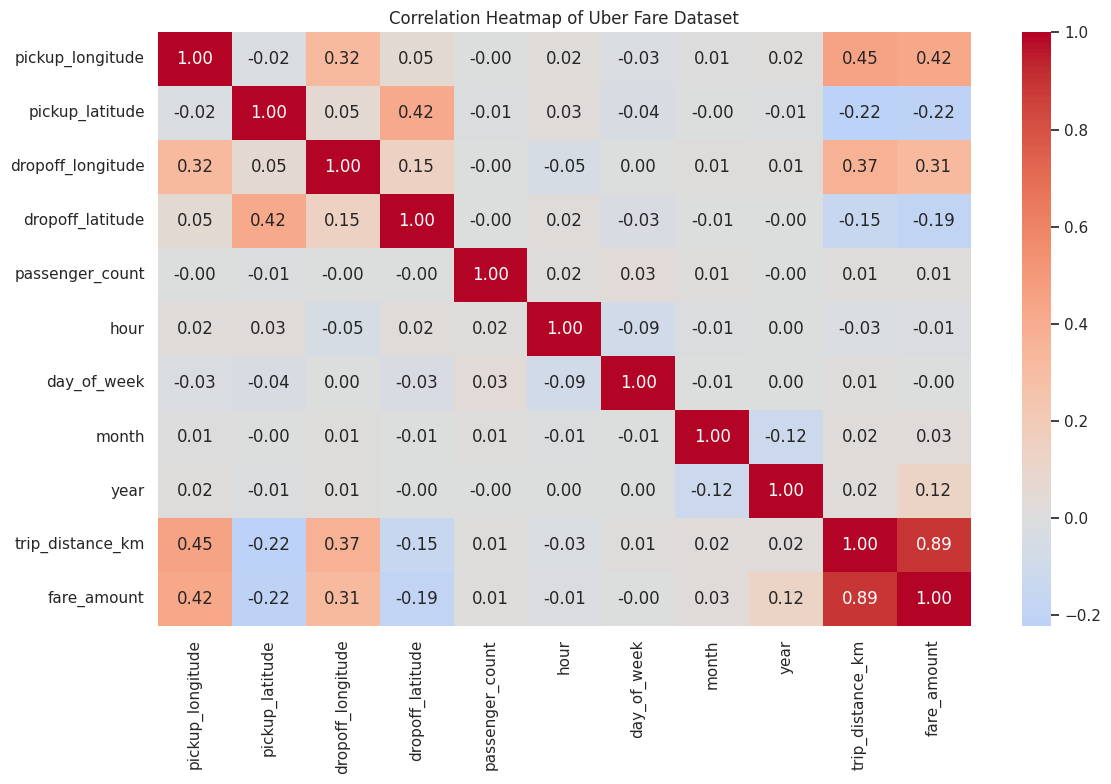

In [10]:
feature_columns = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "hour",
    "day_of_week",
    "month",
    "year",
    "trip_distance_km"
]

correlation_columns = feature_columns + ["fare_amount"]

correlation_matrix = df[correlation_columns].corr()

print("Correlation matrix:")
display(correlation_matrix.round(3))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Uber Fare Dataset")
plt.tight_layout()
plt.show()

Correlation of features with fare amount:


,Correlation with Fare
trip_distance_km,0.891241
pickup_longitude,0.422494
dropoff_longitude,0.312767
year,0.123627
month,0.029796
passenger_count,0.012969
day_of_week,-0.001388
hour,-0.013205
dropoff_latitude,-0.186540
pickup_latitude,-0.216527


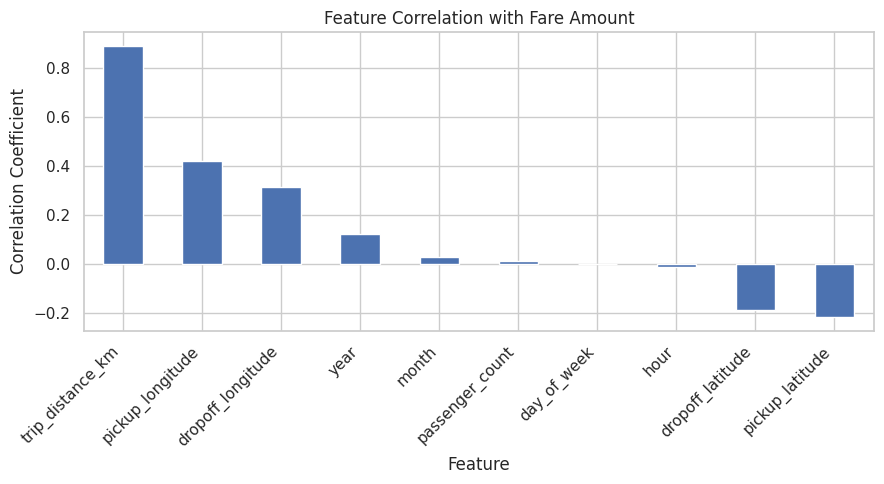

In [11]:
fare_correlation = (
    correlation_matrix["fare_amount"]
    .drop("fare_amount")
    .sort_values(ascending=False)
)

print("Correlation of features with fare amount:")
display(fare_correlation.to_frame("Correlation with Fare"))

plt.figure(figsize=(9, 5))

fare_correlation.plot(kind="bar")

plt.title("Feature Correlation with Fare Amount")
plt.xlabel("Feature")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
X = df[feature_columns]
y = df["fare_amount"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (59997, 10)
Target variable shape: (59997,)


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week,month,year,trip_distance_km
0,-73.999817,40.738354,-73.999512,40.723217,1.0,19,3,5,2015,1.683323
1,-73.994355,40.728225,-73.994710,40.750325,1.0,20,4,7,2009,2.457590
2,-74.005043,40.740770,-73.962565,40.772647,1.0,21,0,8,2009,5.036377
3,-73.976124,40.790844,-73.965316,40.803349,3.0,8,4,6,2009,1.661683
4,-73.925023,40.744085,-73.973082,40.761247,5.0,17,3,8,2014,4.475450


,fare_amount
0,7.5
1,7.7
2,12.9
3,5.3
4,16.0


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 47997
Testing samples: 12000


In [14]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

# Make predictions on the test dataset
y_pred_lr = linear_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_lr[:10])

Linear Regression model trained successfully.
First 10 predictions:
[15.20448084  5.99840012  6.03752355  4.5975324  13.88969217  6.56274471
  7.33945466 49.63628638 15.77302157  9.87452199]


In [15]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully.")

# Make predictions on the test dataset
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_rf[:10])

Random Forest Regression model trained successfully.
First 10 predictions:
[13.50125844  5.91098938  6.54214507  5.3200192  14.21743685  6.73268529
  6.34725474 48.77831548 15.55218506  9.06459786]


In [16]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "R2 Score": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_lr
    )
)

results.append(
    evaluate_model(
        "Random Forest Regression",
        y_test,
        y_pred_rf
    )
)

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

Model Evaluation Results:


,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.8359,3.7974,2.1348
1,Random Forest Regression,0.8847,3.1821,1.7185


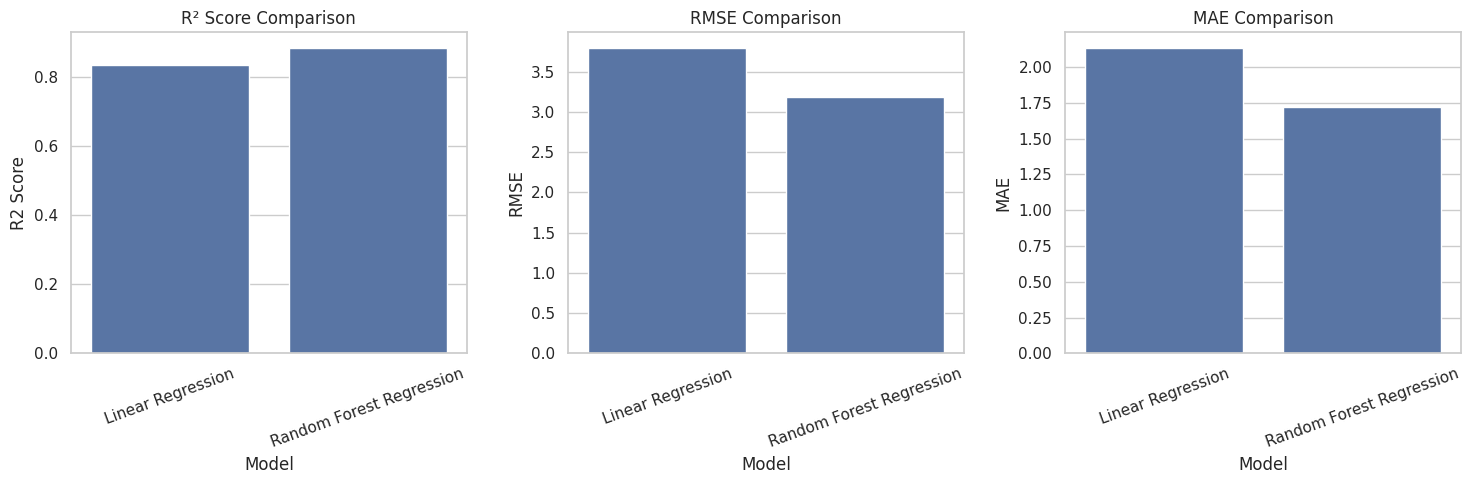

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score",
    ax=axes[0]
)
axes[0].set_title("R² Score Comparison")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[2]
)
axes[2].set_title("MAE Comparison")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [18]:
best_model_row = results_df.loc[results_df["RMSE"].idxmin()]

print("Model comparison summary")
print("------------------------")

print("Best model based on RMSE:", best_model_row["Model"])
print("R2 Score:", round(best_model_row["R2 Score"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("MAE:", round(best_model_row["MAE"], 4))

print("\nFull comparison:")
display(results_df.round(4))

Model comparison summary
------------------------
Best model based on RMSE: Random Forest Regression
R2 Score: 0.8847
RMSE: 3.1821
MAE: 1.7185

Full comparison:


,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.8359,3.7974,2.1348
1,Random Forest Regression,0.8847,3.1821,1.7185


Feature Importance:


,Feature,Importance
9,trip_distance_km,0.8619
2,dropoff_longitude,0.0370
8,year,0.0244
3,dropoff_latitude,0.0201
0,pickup_longitude,0.0199
1,pickup_latitude,0.0118
5,hour,0.0107
7,month,0.0070
6,day_of_week,0.0048
4,passenger_count,0.0025


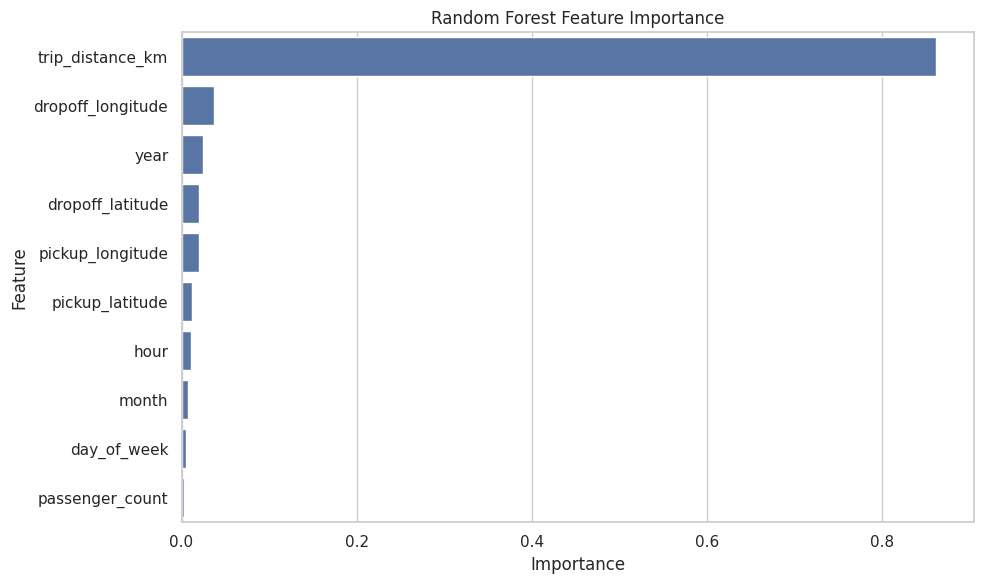

In [19]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [20]:
sample_index = 0

sample_features = X_test.iloc[[sample_index]]

actual_fare = y_test.iloc[sample_index]

lr_prediction = linear_model.predict(sample_features)[0]
rf_prediction = random_forest_model.predict(sample_features)[0]

print("Sample Uber Fare Prediction")
print("---------------------------")

print("Actual fare:", round(actual_fare, 2))
print("Linear Regression prediction:", round(lr_prediction, 2))
print("Random Forest prediction:", round(rf_prediction, 2))

Sample Uber Fare Prediction
---------------------------
Actual fare: 13.7
Linear Regression prediction: 15.2
Random Forest prediction: 13.5


In [21]:
"""Conclusion: The Uber Fares dataset was preprocessed by handling missing values, removing duplicate records, converting timestamps, extracting date and time features, and calculating the approximate distance between pickup and drop-off locations. Outliers were identified using the Interquartile Range (IQR) method and visualized using boxplots. A correlation matrix was plotted to study relationships between numerical features and fare amount.

Linear Regression and Random Forest Regression models were trained using an 80:20 training-testing split. Their performance was evaluated using the R² score, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE). The model with the higher R² score and lower prediction errors performed better on the test set. The feature importance analysis provided further insight into which variables contribute most to Random Forest predictions."""

'Conclusion: The Uber Fares dataset was preprocessed by handling missing values, removing duplicate records, converting timestamps, extracting date and time features, and calculating the approximate distance between pickup and drop-off locations. Outliers were identified using the Interquartile Range (IQR) method and visualized using boxplots. A correlation matrix was plotted to study relationships between numerical features and fare amount.\n\nLinear Regression and Random Forest Regression models were trained using an 80:20 training-testing split. Their performance was evaluated using the R² score, Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE). The model with the higher R² score and lower prediction errors performed better on the test set. The feature importance analysis provided further insight into which variables contribute most to Random Forest predictions.'